# Week 5 – Evaluation
This notebook evaluates saved predictions from the modeling notebook. It reports regression metrics (MAE/RMSE), threshold-based classification metrics, confusion matrices and ROC curves.

## 1. Imports and load predictions

In [8]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error,
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve, confusion_matrix
)

PROCESSED_DIR = Path("../data/processed")
sns.set_style("whitegrid")

pred_path = PROCESSED_DIR / "evaluation_predictions.csv"
if not pred_path.exists():
    raise FileNotFoundError(f"{pred_path} not found. Run the Week 5 modeling notebook first.")
df = pd.read_csv(pred_path)
required_cols = ["actual_rating", "baseline_prediction", "svd_prediction", "ncf_prediction"]
missing = set(required_cols) - set(df.columns)
if missing:
    raise ValueError(f"Missing columns: {missing}")
print("Evaluation dataset shape:", df.shape)
display(df.head())

Evaluation dataset shape: (20341, 4)


,actual_rating,baseline_prediction,svd_prediction,ncf_prediction
0,3.0,3.534237,3.042632,2.953146
1,3.0,3.534237,3.936398,3.970125
2,4.5,3.534237,3.942533,3.891124
3,4.0,3.534237,3.712198,3.664421
4,2.0,3.534237,3.735567,2.979100


## 2. Regression evaluation – MAE and RMSE

In [9]:
y_actual = df["actual_rating"].to_numpy(dtype=float)
predictions = {
    "Baseline (Mean)": df["baseline_prediction"].to_numpy(dtype=float),
    "SVD": df["svd_prediction"].to_numpy(dtype=float),
    "NCF": df["ncf_prediction"].to_numpy(dtype=float)
}
regression_rows = []
for name, scores in predictions.items():
    regression_rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y_actual, scores),
        "RMSE": np.sqrt(mean_squared_error(y_actual, scores))
    })
regression_df = pd.DataFrame(regression_rows)
display(regression_df.round(4))
regression_df.to_csv(PROCESSED_DIR / "regression_metrics.csv", index=False)

,Model,MAE,RMSE
0,Baseline (Mean),0.8340,1.0394
1,SVD,0.6730,0.8691
2,NCF,0.6702,0.8800


## 3. Classification metrics using a rating threshold

In [10]:
THRESHOLD = 4.0
y_true = (y_actual >= THRESHOLD).astype(int)
print("Class distribution (0=Dislike, 1=Like):")
print(pd.Series(y_true).value_counts().sort_index())

classification_rows = []
for name, scores in predictions.items():
    y_pred = (scores >= THRESHOLD).astype(int)
    auc = roc_auc_score(y_true, scores) if len(np.unique(y_true)) == 2 else np.nan
    classification_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": auc
    })
classification_df = pd.DataFrame(classification_rows)
display(classification_df.round(4))
classification_df.to_csv(PROCESSED_DIR / "classification_metrics.csv", index=False)

Class distribution (0=Dislike, 1=Like):
0    10060
1    10281
Name: count, dtype: int64


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Baseline (Mean),0.4946,0.0000,0.0000,0.0000,0.5000
1,SVD,0.6453,0.8225,0.3803,0.5201,0.7779
2,NCF,0.6693,0.7956,0.4652,0.5871,0.7767


## 4. Visual comparison

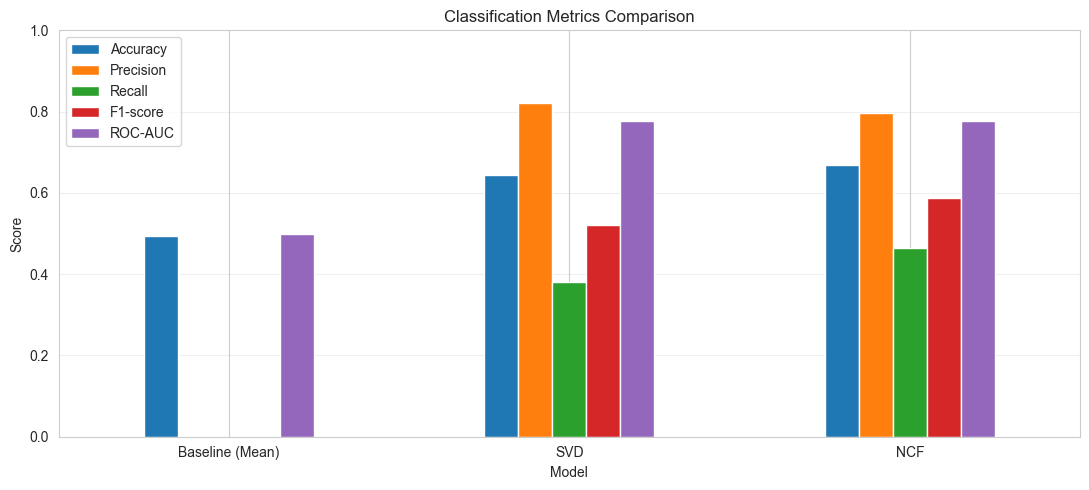

In [11]:
metrics = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
classification_df.set_index("Model")[metrics].plot(kind="bar", figsize=(11, 5), ylim=(0, 1))
plt.title("Classification Metrics Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Confusion matrices

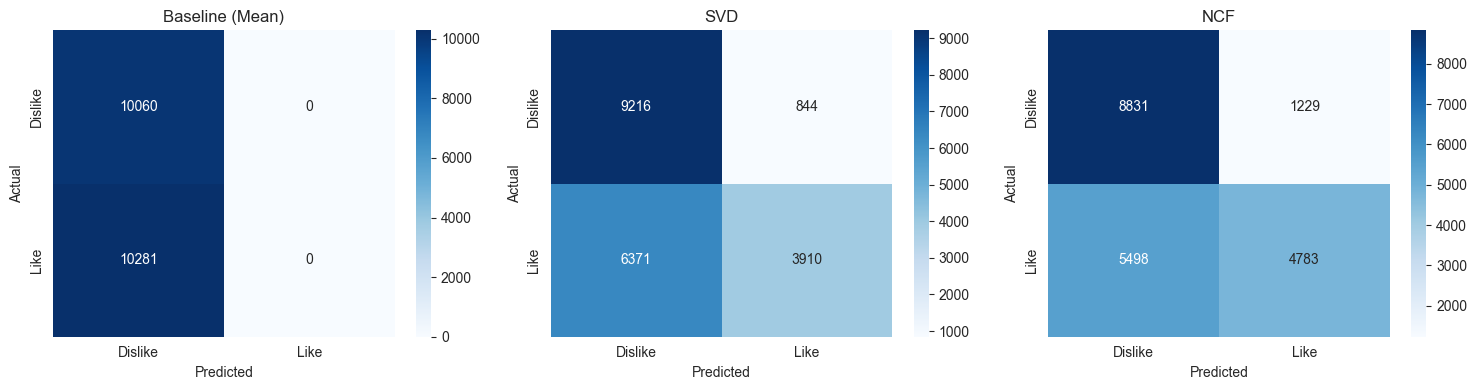

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, scores) in zip(axes, predictions.items()):
    y_pred = (scores >= THRESHOLD).astype(int)
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["Dislike", "Like"], yticklabels=["Dislike", "Like"], ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

## 6. ROC curves

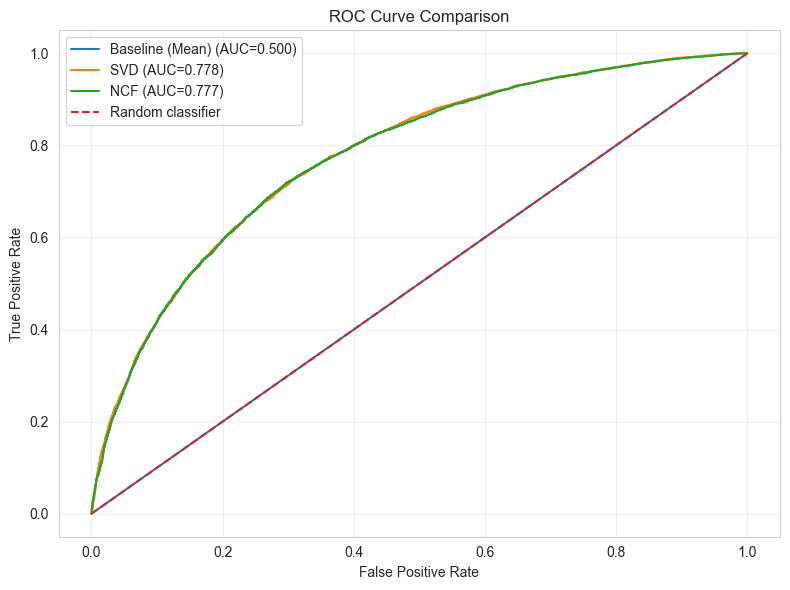

In [13]:
if len(np.unique(y_true)) == 2:
    plt.figure(figsize=(8, 6))
    for name, scores in predictions.items():
        fpr, tpr, _ = roc_curve(y_true, scores)
        auc = roc_auc_score(y_true, scores)
        plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
    plt.plot([0, 1], [0, 1], "--", label="Random classifier")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve Comparison")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("ROC curve requires both classes in y_true.")

## 7. Export combined evaluation table

In [14]:
combined = regression_df.merge(classification_df, on="Model", how="left")
combined.to_csv(PROCESSED_DIR / "week5_complete_evaluation.csv", index=False)
display(combined.round(4))
print("Evaluation files saved in:", PROCESSED_DIR.resolve())

,Model,MAE,RMSE,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Baseline (Mean),0.8340,1.0394,0.4946,0.0000,0.0000,0.0000,0.5000
1,SVD,0.6730,0.8691,0.6453,0.8225,0.3803,0.5201,0.7779
2,NCF,0.6702,0.8800,0.6693,0.7956,0.4652,0.5871,0.7767


Evaluation files saved in: C:\Users\PC\Documents\GitHub\Movie-recommendation-system\Backend\data\processed
